# Por qué medir una prueba: tamaño, potencia y el error de Monte Carlo

**Pregunta:** Cuando la prueba binomial se aplica a una cartera cuya PD es exactamente la correcta, ¿con qué frecuencia rechaza igual al nivel de 5 %, y cuántas repeticiones necesita una medición para que esa tasa sea confiable?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el tema 01 (los cuadernos que abren un artefacto versionado y leen un `TestResult`)
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué son el tamaño y la potencia de una prueba de validación, y por qué una prueba que nunca se corrió sobre datos de verdad conocida tiene tasas de error desconocidas;
- leer una fila del estudio de Contraste como un experimento de simulación: un generador cuya verdad está escrita, una prueba, una semilla y un número de repeticiones;
- hallar el conteo crítico de incumplimientos de una prueba y la probabilidad exacta de que rechace, sin sortear ningún conjunto de datos;
- convertir una tasa de rechazo en una estimación con error de Monte Carlo e intervalo de Wilson, y decir cómo ambos se achican con el número de repeticiones;
- juzgar una tasa contra la cota de tamaño del estudio cuando no existe un valor exacto.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C22 de Contraste, validar al validador, y nada en él es dato de cartera de un banco. Cada conjunto lo sortea un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`), de modo que la verdad detrás de cada número está escrita junto a él. Este cuaderno lee la familia `null`: cada prueba con valor p, corrida sobre datos donde su hipótesis nula se cumple y sus supuestos se satisfacen, así que una prueba correcta debería rechazar cerca del 5 % de las veces al nivel de 5 %.

- **Archivo que se lee:** `data/derived/C22/null.json`, las claves `outputs` (las simulaciones, la configuración de cada generador y las cotas de tamaño) y `provenance`.
- **Qué se toma de él:** la configuración, la semilla y el número de repeticiones de cada fila. El motor vuelve a sortear los conjuntos, aquí, desde esa configuración.

La celda siguiente carga el archivo, indexa las filas por clave e imprime la versión del motor que escribió el archivo junto a la instalada.

In [2]:
# Cargar la familia nula del caso C22 e indexar sus simulaciones por clave
LANG = "es"
ROOT = Path("../../..").resolve()
null = json.loads((ROOT / "data" / "derived" / "C22" / "null.json").read_text(encoding="utf-8"))
out = null["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
print("simulaciones en el archivo:", len(rows))
print("calculado con riskvalidation", null["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)

simulaciones en el archivo: 53
calculado con riskvalidation 1.0.1 | instalado 1.0.1


## Método

Un estudio de simulación es un experimento, y Morris, White y Crowther (2019) dan a su informe cinco partes: objetivos, mecanismos generadores de datos, estimandos, métodos y medidas de desempeño. En las filas de Contraste el objetivo es la pregunta «¿esta prueba mantiene su tamaño?», el mecanismo es un generador con una verdad declarada, el estimando es la probabilidad de que la prueba rechace al nivel $\alpha$, el método es una prueba registrada con la regla `p<0.05` o `p<0.01`, y la medida de desempeño es la tasa de rechazo con su error.

El tamaño de una prueba es su probabilidad de rechazo cuando la hipótesis nula es verdadera. La potencia es su probabilidad de rechazo cuando se planta un defecto de severidad conocida. Ambas son probabilidades, así que una simulación solo puede estimarlas, y una prueba de conteo además puede tenerlas calculadas de forma exacta. Los pasos siguientes construyen una fila desde su configuración, calculan su tamaño exacto, estiman el mismo tamaño por simulación, comparan ambos y miran cómo la estimación se asienta al crecer las repeticiones.

### Paso 1: una fila, leída como experimento

La fila `pd.binomial@null` es la prueba binomial sobre una cartera de 1.000 deudores cuya PD de 1 % es exactamente la correcta. La clase del generador es `DefaultCounts`; la configuración del archivo basta para construirlo, y su método `truth()` dice qué son los datos. La celda siguiente lo construye e imprime la verdad, la prueba, las repeticiones y la semilla.

In [3]:
# Reconstruir el generador desde su configuración y leer su verdad
from riskvalidation.generators.counts import DefaultCounts, feed_cell

row = rows["pd.binomial@null"]
spec = out["generators"][row["generator"]]
generator = DefaultCounts(**spec["config"])
truth = generator.truth()
print("deudores:", truth["obligors"][0][0], "| PD:", truth["pd_true"][0][0])
print("PD aplicada:", truth["pd_forecast"][0][0])
print("incumplimientos esperados:", truth["expected_defaults"][0][0])
print("varianza del conteo:", truth["variance_defaults"][0][0])
print("la nula se cumple en la frontera:", truth["calibration_null_holds"])
print("prueba:", row["test_id"], "| repeticiones:", row["n_rep"], "| semilla:", row["seed"])

deudores: 1000 | PD: 0.01
PD aplicada: 0.01
incumplimientos esperados: 10.0
varianza del conteo: 9.9
la nula se cumple en la frontera: True
prueba: pd.binomial | repeticiones: 4000 | semilla: 3913381310


La verdad dice que cada sorteo tiene 1.000 deudores con una PD verdadera de 1 % e igual PD aplicada, así que se esperan 10 incumplimientos y, con deudores independientes, el conteo tiene una varianza de 9,9. Como la PD aplicada es la verdadera, la hipótesis nula se cumple en su frontera y todo rechazo de la prueba es una falsa alarma. Eso hace de la fila una medición de tamaño, y la semilla con las 4000 repeticiones la vuelve repetible.

### Paso 2: el tamaño exacto, sin simular

Una prueba de conteo ve la cartera solo a través del número de incumplimientos $D$. El motor halla el menor conteo $k^*$ cuyo valor p cae bajo $\alpha$ llamando a la propia prueba registrada, y la prueba rechaza exactamente cuando $D \ge k^*$. Como $D$ es discreto, el tamaño verdadero es la probabilidad de cola

$$P(\text{rechazo}) = P(D \ge k^*), \qquad D \sim \mathrm{Binomial}(n, \pi),$$

que pocas veces es igual a $\alpha$. La celda siguiente pide la probabilidad de cada conteo con `count_pmf`, el conteo crítico con `critical_count` y el tamaño exacto con `rejection_probability`, y dibuja la distribución con la región de rechazo en rojo.

conteo crítico al 5 %: 16 | tamaño exacto: 0.04787


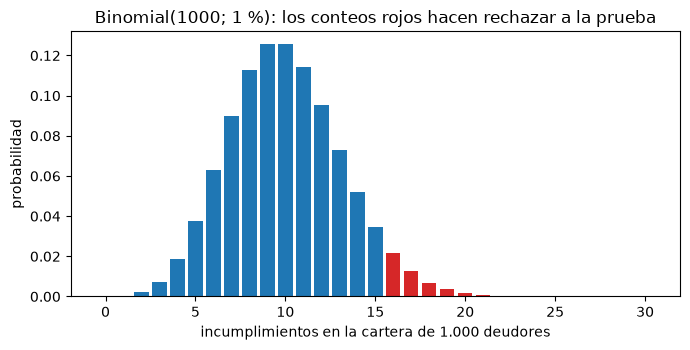

In [4]:
# Probabilidad de cada conteo, conteo crítico y tamaño exacto de la prueba
from riskvalidation.harness.exact import count_pmf, critical_count, rejection_probability

pmf = count_pmf(1000, 0.01)
k_star = critical_count("pd.binomial", 1000, 0.01, 0.05)
size = rejection_probability("pd.binomial", 1000, 0.01, 0.05)["probability"]
print("conteo crítico al 5 %:", k_star, "| tamaño exacto:", round(size, 5))
ks = np.arange(0, 31)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(ks, pmf[:31], color=np.where(ks >= k_star, "tab:red", "tab:blue"))
ax.set_xlabel("incumplimientos en la cartera de 1.000 deudores")
ax.set_ylabel("probabilidad")
ax.set_title("Binomial(1000; 1 %): los conteos rojos hacen rechazar a la prueba")
fig.tight_layout()
plt.show()

Las barras rojas empiezan en 16 incumplimientos: con 10 esperados, la prueba necesita seis más de los esperados antes de declarar errónea la PD. El área roja suma 0,04787, de modo que la prueba rechaza un modelo correcto el 4,79 % de las veces, no el 5 %. La diferencia es el precio de un conteo discreto, donde ningún umbral entero tiene una cola de exactamente 5 %. Este valor exacto es la referencia contra la cual se leerá la tasa simulada de los pasos siguientes.

### Paso 3: la tasa simulada es una estimación

Con $n$ repeticiones y $k$ rechazos la tasa $\hat r = k/n$ estima la probabilidad de rechazo. Su error estándar de Monte Carlo es $\sqrt{\hat r(1-\hat r)/n}$ (Morris, White y Crowther, 2019, tabla 6), y el intervalo de Wilson, recomendado por Brown, Cai y DasGupta (2001) para una proporción binomial, se porta bien cerca de cero, donde viven los tamaños pequeños. El `simulate` del motor sortea los conjuntos, corre la prueba en cada uno y devuelve objetos `Rate` que guardan los conteos. La celda siguiente corre la fila con su semilla y escribe la tasa, su error y su intervalo.

In [5]:
# Repetir la fila con su semilla y leer la tasa, su error y su intervalo de Wilson
from riskvalidation.harness.run import simulate

sim = simulate(row["test_id"], generator, n_rep=row["n_rep"], seed=row["seed"], feed=feed_cell())
rate = sim.rates["p<0.05"]
low, high = rate.interval
print("rechazos:", rate.rejections, "de", rate.n)
print("tasa al 5 %:", rate.rate, "| error de Monte Carlo:", round(rate.se, 5))
print("intervalo de Wilson:", round(low, 5), "a", round(high, 5))
print("error por la fórmula:", round(float(np.sqrt(rate.rate * (1 - rate.rate) / rate.n)), 5))

rechazos: 182 de 4000
tasa al 5 %: 0.0455 | error de Monte Carlo: 0.0033
intervalo de Wilson: 0.03947 a 0.05241
error por la fórmula: 0.0033


La prueba rechazó 182 de las 4000 repeticiones, una tasa de 0,0455. El error de 0,0033 coincide con la fórmula, y el intervalo de Wilson va de 0,03947 a 0,05241. El tamaño exacto de 0,04787 cae dentro de ese intervalo, así que la simulación y el cálculo cuentan una sola historia. Una tasa citada sin su error o su intervalo no puede leerse, porque los mismos 182 rechazos podrían venir de un tamaño cualquiera entre casi 3,9 % y 5,2 %.

### Paso 4: ¿concuerda la simulación con el valor exacto?

Cuando existe una probabilidad exacta $p$, el `agrees` del motor acepta una tasa simulada si

$$|\hat r - p| \le z\,\sqrt{p(1-p)/n}, \qquad z = 3{,}29,$$

el punto bilateral de 0,1 %. El $z$ ancho es deliberado, porque el estudio hace decenas de comparaciones así y uno estrecho marcaría ruido. La celda siguiente simula las pruebas binomial y de Jeffreys al 5 % y al 1 %, calcula el tamaño exacto de cada una, escribe la brecha estandarizada $z$ y el veredicto de `agrees`, y dibuja cada tasa con su intervalo junto al valor exacto.

pd.binomial  0.05 | simulada 0.04550 | exacto 0.04787 | z -0.70 | True
pd.binomial  0.01 | simulada 0.00600 | exacto 0.00690 | z -0.69 | True
pd.jeffreys  0.05 | simulada 0.03900 | exacto 0.04787 | z -2.63 | True
pd.jeffreys  0.01 | simulada 0.01125 | exacto 0.01383 | z -1.40 | True


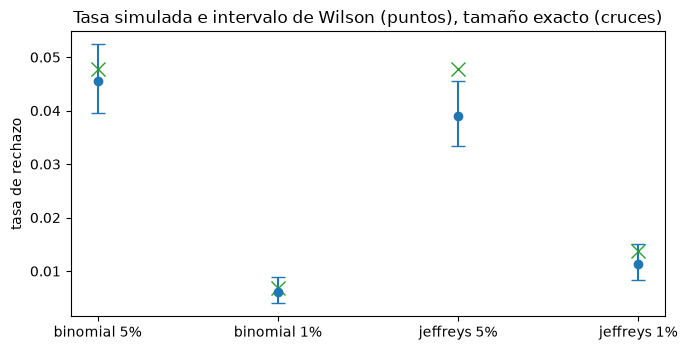

In [6]:
# Simular dos pruebas de conteo en dos niveles y poner cada tasa junto a su tamaño exacto
from riskvalidation.harness.rates import agrees

points = []
for test in ("pd.binomial", "pd.jeffreys"):
    run = simulate(test, generator, n_rep=4000, seed=rows[f"{test}@null"]["seed"], feed=feed_cell())
    for alpha in (0.05, 0.01):
        measured = run.rates[f"p<{alpha}"]
        exact = rejection_probability(test, 1000, 0.01, alpha)["probability"]
        gap = (measured.rate - exact) / np.sqrt(exact * (1 - exact) / measured.n)
        points.append((f"{test[3:]} {alpha:.0%}", measured, exact))
        verdict = agrees(measured, exact)
        print(f"{test:12s} {alpha:.2f} | simulada {measured.rate:.5f} | exacto {exact:.5f} | z {gap:+.2f} | {verdict}")
fig, ax = plt.subplots(figsize=(7, 3.6))
for position, (label, measured, exact) in enumerate(points):
    low, high = measured.interval
    errors = [[measured.rate - low], [high - measured.rate]]
    ax.errorbar(position, measured.rate, yerr=errors, fmt="o", capsize=5, color="tab:blue")
    ax.plot(position, exact, "x", color="tab:green", markersize=10)
ax.set_xticks(range(len(points)))
ax.set_xticklabels([p[0] for p in points])
ax.set_ylabel("tasa de rechazo")
ax.set_title("Tasa simulada e intervalo de Wilson (puntos), tamaño exacto (cruces)")
fig.tight_layout()
plt.show()

Las cuatro tasas simuladas concuerdan con sus valores exactos, y la mayor brecha estandarizada es -2,63, para la prueba de Jeffreys al 5 %, dentro del límite de 3,29. La prueba de Jeffreys es además la que hay que vigilar: su tamaño exacto al nivel de 1 % es 0,01383, sobre el 1 % nominal, mientras que la binomial queda bajo él con 0,00690. Una simulación que coincide con un valor exacto es evidencia de que el generador, el arnés y la prueba están conectados como se pretende, y por eso el estudio revisa cada fila que lo tiene.

### Paso 5: una cota de tamaño para las pruebas sin valor exacto

La mayoría de las pruebas no tiene una probabilidad de rechazo exacta. Para ellas la pregunta es unilateral: ¿es la tasa compatible con un tamaño verdadero de a lo más $\alpha$? El motor responde con la cota $\alpha + z\sqrt{\alpha(1-\alpha)/n}$ con $z = 3{,}09$, el punto unilateral de 0,1 %, y `within_size` compara una tasa con ella. La celda siguiente escribe la cota para 4000 repeticiones y aplica `within_size` a cuatro filas: las pruebas binomial y de Jeffreys, la prueba del índice de estabilidad poblacional (PSI) sobre dos muestras de 1.000, y la prueba normal a cinco años. Cada generador se reconstruye desde el archivo y cada fila corre con su propia semilla.

In [7]:
# Aplicar la cota de tamaño de 4000 repeticiones a la tasa de cuatro pruebas
from riskvalidation.generators.counts import feed_series
from riskvalidation.generators.drift import TwoSample
from riskvalidation.harness.rates import size_bound, within_size

CLASSES = {cls.name: cls for cls in (DefaultCounts, TwoSample)}
print("cota al 5 %:", round(size_bound(0.05, 4000), 5), "| cota al 1 %:", round(size_bound(0.01, 4000), 5))
for key in ("pd.binomial@null", "stability.psi@null", "pd.normal_multiperiod@null", "pd.jeffreys@null"):
    item = rows[key]
    cfg = out["generators"][item["generator"]]
    gen = CLASSES[cfg["name"]](**cfg["config"])
    years = len(cfg["config"].get("obligors", [[0]]))
    feed = feed_series() if years > 1 else (feed_cell() if cfg["name"] == "default_counts" else None)
    run = simulate(item["test_id"], gen, n_rep=item["n_rep"], seed=item["seed"], feed=feed)
    measured = run.rates["p<0.05"]
    print(f"{item['test_id']:24s} tasa al 5 % {measured.rate:.5f} | dentro de la cota {within_size(measured, 0.05)}")

cota al 5 %: 0.06065 | cota al 1 %: 0.01486
pd.binomial              tasa al 5 % 0.04550 | dentro de la cota True
stability.psi            tasa al 5 % 0.05250 | dentro de la cota True
pd.normal_multiperiod    tasa al 5 % 0.08375 | dentro de la cota False
pd.jeffreys              tasa al 5 % 0.03900 | dentro de la cota True


Con 4000 repeticiones, una tasa sobre 0,06065 al nivel de 5 % no es ruido de Monte Carlo. Las pruebas binomial, de Jeffreys y del PSI quedan dentro, con 0,04550, 0,03900 y 0,05250. La prueba normal a cinco años llega a 0,08375 y cae fuera: rechaza un modelo correcto casi el doble de veces de lo que promete. Es la primera señal de que no toda prueba mantiene su tamaño, una pregunta que el cuaderno siguiente del tema responde para las veintiuna pruebas.

### Paso 6: el error de Monte Carlo se achica con las repeticiones

La repetición $i$ siempre sortea desde su propia corriente de la semilla, de modo que una corrida de 100 repeticiones es las primeras 100 de una de 4000. Eso arma un experimento limpio: el mismo estudio detenido en cuatro largos. El error estándar cae como $1/\sqrt{n}$, así que una corrida cuatro veces más larga tiene un intervalo de la mitad de ancho. La celda siguiente corre la fila binomial con 100, 400, 1.600 y 4.000 repeticiones y dibuja cada tasa con su intervalo de Wilson junto al tamaño exacto y al 5 % nominal.

n_rep   100 | tasa 0.0600 | error 0.0237 | ancho del intervalo 0.0970
n_rep   400 | tasa 0.0425 | error 0.0101 | ancho del intervalo 0.0403
n_rep  1600 | tasa 0.0500 | error 0.0054 | ancho del intervalo 0.0214
n_rep  4000 | tasa 0.0455 | error 0.0033 | ancho del intervalo 0.0129


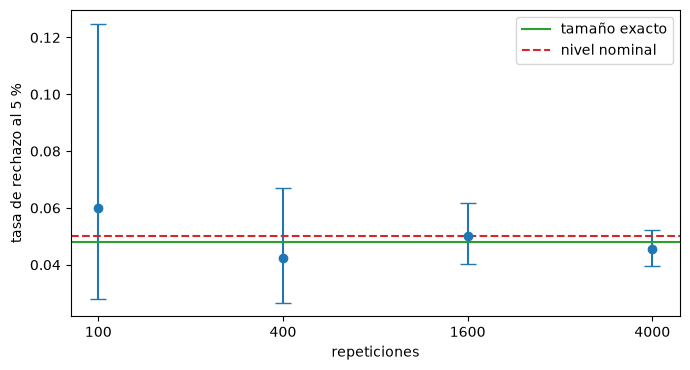

In [8]:
# Detener el mismo estudio en cuatro largos y dibujar cada tasa con su intervalo
lengths = (100, 400, 1600, 4000)
fig, ax = plt.subplots(figsize=(7, 3.8))
for position, n_rep in enumerate(lengths):
    run = simulate("pd.binomial", generator, n_rep=n_rep, seed=row["seed"], feed=feed_cell())
    r = run.rates["p<0.05"]
    low, high = r.interval
    print(f"n_rep {n_rep:5d} | tasa {r.rate:.4f} | error {r.se:.4f} | ancho del intervalo {high - low:.4f}")
    ax.errorbar(position, r.rate, yerr=[[r.rate - low], [high - r.rate]], fmt="o", capsize=6, color="tab:blue")
ax.axhline(size, color="tab:green", label="tamaño exacto")
ax.axhline(0.05, color="tab:red", linestyle="--", label="nivel nominal")
ax.set_xticks(range(len(lengths)))
ax.set_xticklabels([str(n) for n in lengths])
ax.set_xlabel("repeticiones")
ax.set_ylabel("tasa de rechazo al 5 %")
ax.legend()
fig.tight_layout()
plt.show()

El intervalo mide 0,0970 de ancho con 100 repeticiones, 0,0403 con 400, 0,0214 con 1600 y 0,0129 con 4000, de modo que cada paso de cuatro veces lo reduce a la mitad. Con 100 repeticiones la tasa de 0,0600 no distingue un tamaño de 4,8 % de uno de 6 %, pues el intervalo cubre ambos y también el 5 % nominal. Solo la corrida más larga acota el intervalo a cerca de un punto, y por eso el estudio usa 4000 repeticiones para los tamaños y publica el intervalo junto a cada tasa.

## Resultados

**Respuesta:** La prueba binomial rechaza un modelo correcto el 0,0455 de las veces en la simulación, 182 rechazos en 4000 repeticiones, contra un tamaño exacto de 0,04787 calculado desde su conteo crítico de 16 incumplimientos; el error de Monte Carlo de 0,0033 y el intervalo de Wilson de 0,03947 a 0,05241 muestran que ambos concuerdan. Una medición así necesita miles de repeticiones: el intervalo mide 0,0970 con 100 repeticiones y 0,0129 con 4000, así que solo la corrida larga separa con algo de precisión el 0,0455 del 0,05 nominal.

- **El nivel nominal no es el tamaño.** La prueba binomial se construye para 5 % pero rechaza desde 16 incumplimientos, una cola de 0,04787, porque el conteo es discreto. Al nivel de 1 % los tamaños exactos son 0,00690 para la binomial y 0,01383 para la de Jeffreys, que queda sobre su nivel nominal en esta cartera sin que intervenga ninguna simulación.
- **Simulación y valor exacto concuerdan.** La mayor brecha estandarizada de las cuatro comparaciones es -2,63, dentro del criterio de 3,29 de `agrees`.
- **Una cota para el resto.** Con 4000 repeticiones un tamaño sobre 0,06065 no es ruido. La prueba del PSI queda dentro de la cota con 0,05250 y la prueba normal a cinco años queda fuera con 0,08375.

Este cuaderno no muestra la potencia de ninguna prueba, el tamaño de las otras veinte pruebas ni lo que hacen los incumplimientos correlacionados a la prueba binomial; los cuadernos siguientes del tema los retoman.

## Resumen

- El tamaño de una prueba es su tasa de rechazo cuando se cumple su nula, y su potencia es la tasa frente a un defecto plantado de severidad conocida; ambas son probabilidades que una simulación estima.
- Una fila del estudio lleva sus cinco partes: objetivo, generador con una verdad escrita, estimando, prueba registrada y medidas de desempeño.
- Para una prueba de conteo el motor calcula el conteo crítico y el tamaño exacto, que la tasa simulada debe igualar dentro de su error de Monte Carlo.
- Una tasa se lee con su error y su intervalo de Wilson, y ambos caen con la raíz cuadrada de las repeticiones.
- Sin valor exacto, la cota de tamaño del estudio distingue el ruido de un tamaño sobre el nivel.

**Qué probar después.** Repite los mismos pasos con `pd.jeffreys` y una PD de 0,5 % y mira cambiar el conteo crítico; luego lee el cuaderno 02, que mide las veintiuna pruebas.

## Referencias

- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sección 2.5.3.1 (la prueba de Jeffreys). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Este repositorio: `docs/design/features/c22-validator/requirements.md` (los requisitos que sostienen las mediciones de C22) y `data-pipeline/pipeline/cases/c22_validator.py` (el cálculo que escribió el artefacto).